In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

Load Dataset

In [2]:
iris = load_iris()

#Create the Dataframe
df=pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

#Target Species
df["species"]=iris.target


In [3]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Understanding Dataset

In [4]:
#Display Number of Rows and Columns
print("Dataset Shape:", df.shape)

Dataset Shape: (150, 5)


In [5]:
#Display columns names and Data types
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [6]:
#Missing Values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [7]:
#Diplay Statistical Summary
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)     species  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  


In [8]:
#Display Species Distribution
print("Species Distribution:")
print(df["species"].value_counts())

Species Distribution:
species
0    50
1    50
2    50
Name: count, dtype: int64


Convert Species Numbers into Names

In [9]:
#Replace Numerical Species labels with actual names
df["species"]=df["species"].map({
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
})


In [10]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


Exploratory Data Analysis

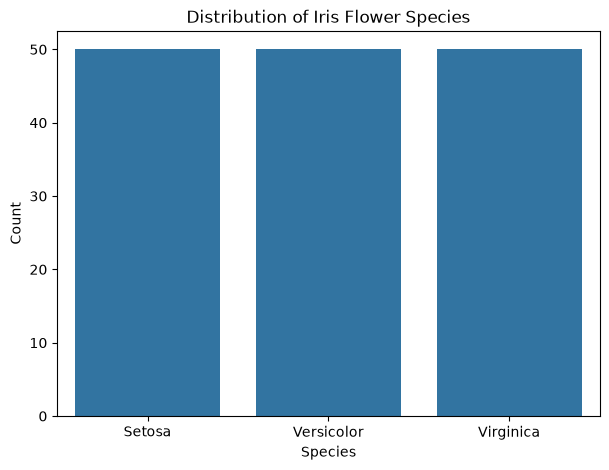

In [11]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

Pairplot

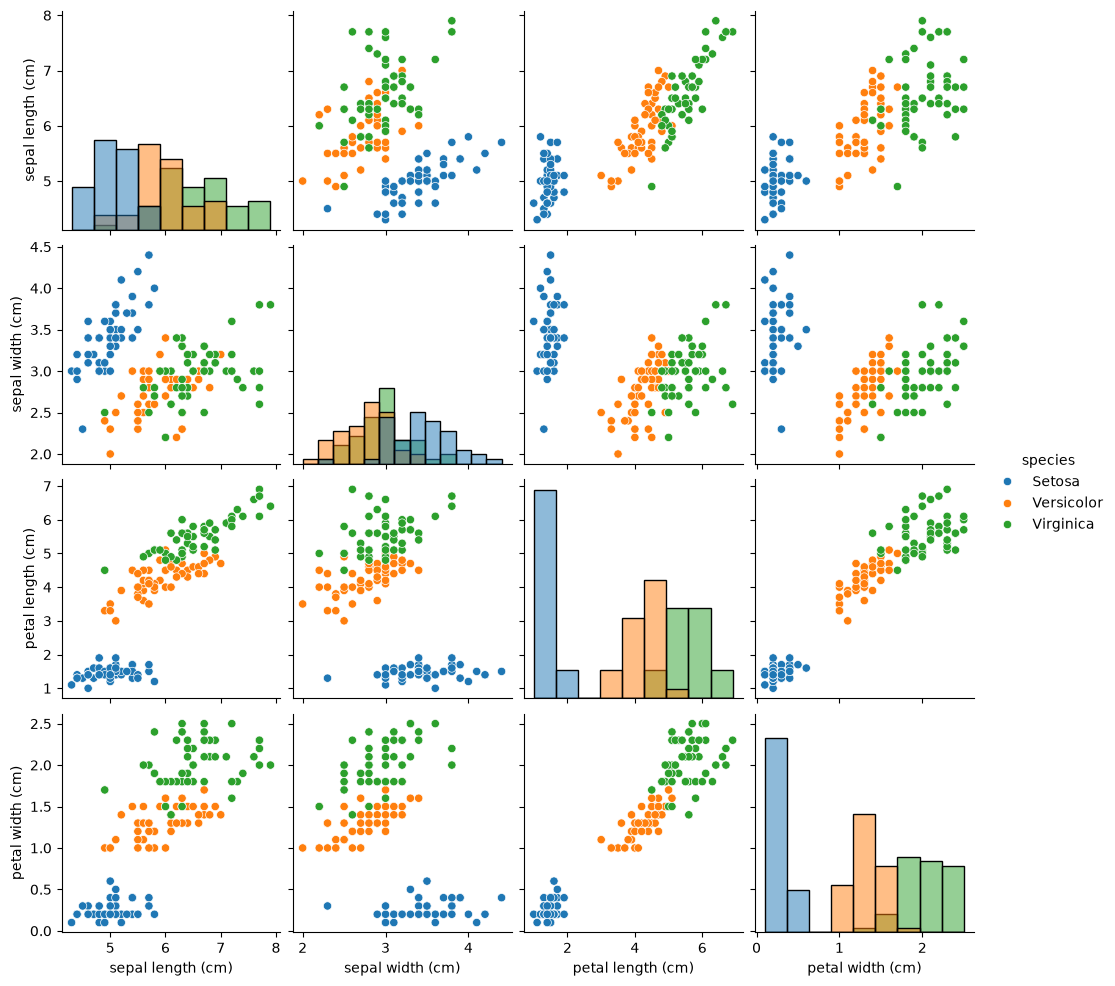

In [12]:
#Visualize Relationships between all flower measurements

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

Boxplots for all Features

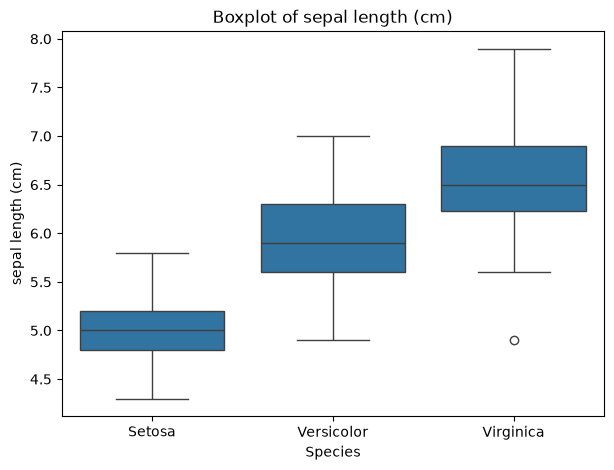

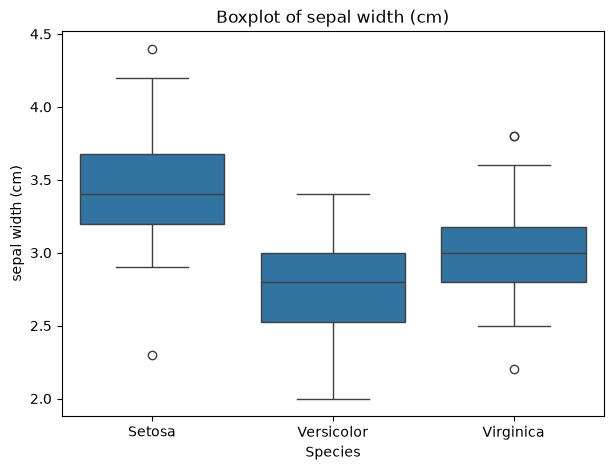

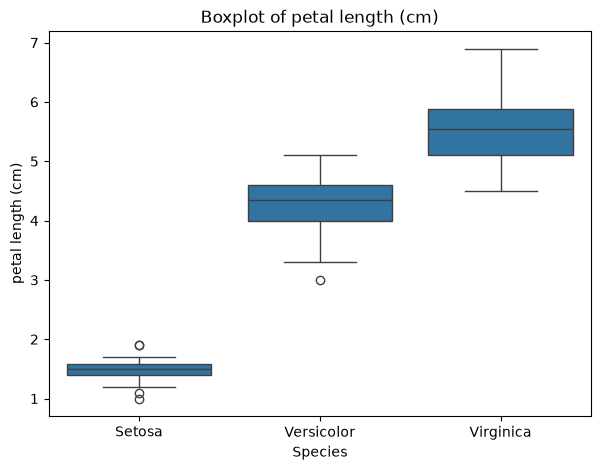

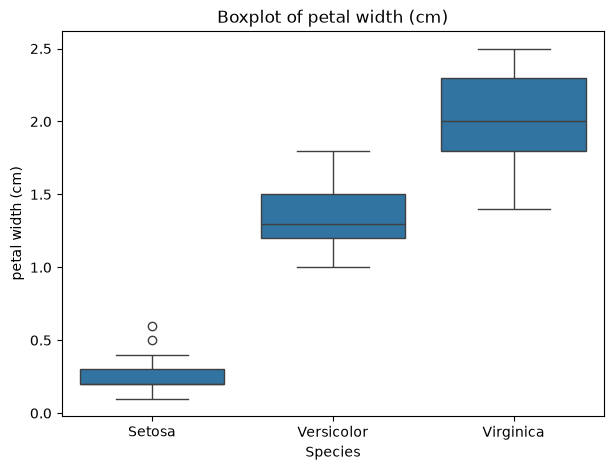

In [13]:
features=iris.feature_names

for feature in features:

    plt.figure(figsize=(7,5))

    sns.boxplot(
        data=df,
        x="species",
        y=feature
    )

    plt.title("Boxplot of " + feature)
    plt.xlabel("Species")
    plt.ylabel(feature)

    plt.show()

Correlation Heatmap

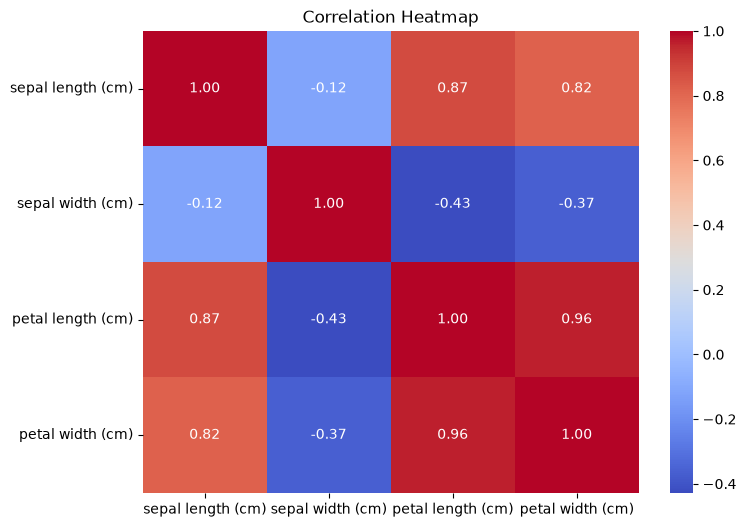

In [14]:
correlation=df[features].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Data Preparation

In [15]:
#Separate input features and target variable
X=df[features]
y=df["species"]

#Split dataset into training and testing sets
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


Feature Scaling

In [16]:
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)

X_test_scaled=scaler.transform(X_test)

Logistic Regression

In [17]:
logistic_model=LogisticRegression(max_iter=200)

#Train Model
logistic_model.fit(X_train_scaled, y_train)

#Predictions
logistic_predictions=logistic_model.predict(X_test_scaled)

K-Nearest Neighbors

In [18]:
knn_model=KNeighborsClassifier(n_neighbors=5)

#Train Model
knn_model.fit(X_train_scaled, y_train)

#Make Predictions
knn_predictions=knn_model.predict(X_test_scaled)

Model Evaluation

In [19]:
#Accuracy Comparision
#logistic Regression
logistic_accuracy=accuracy_score(
    y_test,
    logistic_predictions
)

#KNN 
knn_accuracy=accuracy_score(
    y_test,
    knn_predictions
)

print("Logistic Regression Accuracy:",
     round(logistic_accuracy *100, 2), "%")

print("KNN Accuracy:",
     round(knn_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 93.33 %
KNN Accuracy: 93.33 %


Classification Reports

In [20]:
print("Logistic Regression Classification Report")

print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

print("\nKNN Classification Report")

print(
    classification_report(
        y_test,
        knn_predictions
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.90      0.90      0.90        10
   Virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


KNN Classification Report
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       0.83      1.00      0.91        10
   Virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



Confusion Matrix

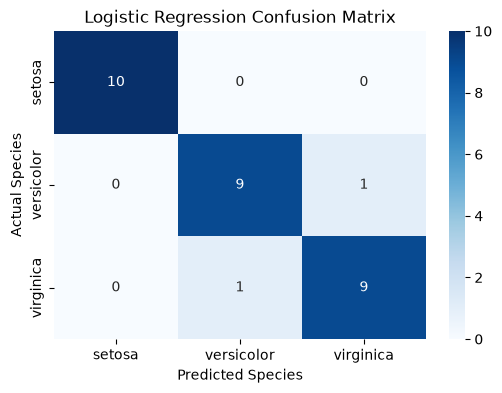

In [21]:
#Logistic Regression Confusion Matrix
plt.figure(figsize=(6,4))

sns.heatmap(
    confusion_matrix(y_test, logistic_predictions),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

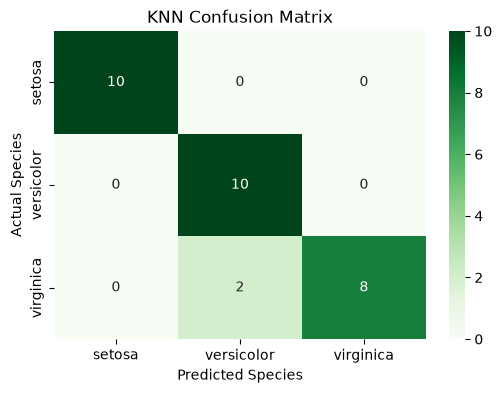

In [22]:
#KNN Confusion Matrix
plt.figure(figsize=(6,4))

sns.heatmap(
    confusion_matrix(y_test, knn_predictions),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

Compare Both Models

In [23]:
#Compare Model Accuracy

results=pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors"
    ],

    "Accuracy": [
        logistic_accuracy,
        knn_accuracy
    ]
})

print(results)

#Find the Model with Highest Accuracy
best_model_name=results.loc[
    results["Accuracy"].idxmax(),
    "Model"
]

print("Best Performing Model:", best_model_name)

                 Model  Accuracy
0  Logistic Regression  0.933333
1  K-Nearest Neighbors  0.933333
Best Performing Model: Logistic Regression


Test with a new Flower

In [24]:
#Select Best-performing Model

if logistic_accuracy >= knn_accuracy:
    best_model = logistic_model
else:
    best_model = knn_model

#New Flower Measurements:
new_flower=pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=features
)

#Scale new flower measurements
new_flower_scaled=scaler.transform(new_flower)

#predict flower species
prediction=best_model.predict(new_flower_scaled)

print("Predicted Flower Species:", prediction[0])

Predicted Flower Species: Setosa
